<a href="https://colab.research.google.com/github/CHIN-HUA/AI/blob/main/A2_415511001.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2 — The Morning Rush

**學號 415511001　姓名 嚴佳華**

台北 YouBike 每小時租借量預測。全部使用線性模型，所有前處理都在 `Pipeline` 內、
只以訓練資料 fit，隨機種子固定為 0。

- Part I　最小平方法與 Ridge 手算
- Part II　特徵工程與特徵縮放
- Part III　學習曲線診斷與排行榜預測

驗證集為 `train.csv` 的最後一個月（5 月），1–4 月為訓練集，選模完成後以 1–5 月全部資料重訓。

In [1]:
# 環境與資料載入
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (MinMaxScaler, OneHotEncoder,
                                   PolynomialFeatures, StandardScaler)

SEED = 0
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.dpi"] = 110

try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REQUIRED = ["train.csv", "test.csv", "sample_submission.csv"]

def locate_data():
    for folder in [Path("."), Path("data"), Path("/content"), Path("/content/data")]:
        if all((folder / name).is_file() for name in REQUIRED):
            return folder
    return None

DATA_DIR = locate_data()
if DATA_DIR is None and IN_COLAB:
    print("請選取 train.csv、test.csv、sample_submission.csv（可一次多選）")
    colab_files.upload()
    DATA_DIR = locate_data()
if DATA_DIR is None:
    raise FileNotFoundError("找不到三個 CSV，請放到 notebook 同一層或 data/ 之下。")

train_all = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["datetime"])
test_df = pd.read_csv(DATA_DIR / "test.csv", parse_dates=["datetime"])
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

WEATHER = ["temperature", "precipitation", "humidity", "wind_speed"]
FEATURE_COLS = ["datetime", "station", "district", "capacity", "is_holiday"] + WEATHER
TARGET = "rentals"

is_may = train_all["datetime"].dt.month == 5
train_df = train_all.loc[~is_may].reset_index(drop=True)   # 1-4 月
val_df = train_all.loc[is_may].reset_index(drop=True)      # 5 月

print(f"sklearn {__import__('sklearn').__version__} | seed {SEED} | Colab={IN_COLAB}")
print(f"訓練 1-4 月 {len(train_df):,} 筆 | 驗證 5 月 {len(val_df):,} 筆 | 測試 6 月 {len(test_df):,} 筆")
print(f"站點 {train_all['station'].nunique()} 個，行政區 {train_all['district'].nunique()} 個")

請選取 train.csv、test.csv、sample_submission.csv（可一次多選）


Saving sample_submission.csv to sample_submission.csv
Saving test.csv to test.csv
Saving train.csv to train.csv
sklearn 1.6.1 | seed 0 | Colab=True
訓練 1-4 月 86,400 筆 | 驗證 5 月 22,320 筆 | 測試 6 月 21,600 筆
站點 30 個，行政區 9 個


---
# Part I　Least Squares by Hand

## (a) Ridge 解與唯一性

目標函數

$$J(w)=\tfrac12\lVert y-Xw\rVert_2^2+\tfrac{\lambda}{2}\lVert w\rVert_2^2$$

對 $w$ 微分：

$$\nabla J(w)=X^\top(Xw-y)+\lambda w$$

令梯度為零：

$$(X^\top X+\lambda I)\,w=X^\top y
\qquad\Longrightarrow\qquad
w^{*}=(X^\top X+\lambda I)^{-1}X^\top y$$

**唯一性**：對任意非零向量 $v$，

$$v^\top(X^\top X+\lambda I)v=\lVert Xv\rVert_2^2+\lambda\lVert v\rVert_2^2>0$$

因為 $\lambda>0$ 且 $\lVert v\rVert^2>0$。所以 $X^\top X+\lambda I$ 正定、必可逆，
即使 $X^\top X$ 奇異（特徵共線或 $d>N$）解仍然唯一。

## 題目的五筆資料

| Hour | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| 雨量 $x$ (mm) | 0 | 1 | 2 | 3 | 4 |
| 租借 $y$ | 10 | 8 | 7 | 4 | 1 |

截距不受懲罰，所以先中心化再求斜率：$w_1=S_{xy}/(S_{xx}+\lambda)$，$w_0=\bar y-w_1\bar x$。

In [2]:
# Part I (a)：toy 資料的 OLS 與 Ridge
x = np.array([0., 1., 2., 3., 4.])
y = np.array([10., 8., 7., 4., 1.])

xbar, ybar = x.mean(), y.mean()
Sxx = ((x - xbar) ** 2).sum()
Sxy = ((x - xbar) * (y - ybar)).sum()
Syy = ((y - ybar) ** 2).sum()
print(f"x_bar={xbar:g}  y_bar={ybar:g}  Sxx={Sxx:g}  Sxy={Sxy:g}  Syy={Syy:g}")

rows = []
for lam in [0.0, 1.0, 10.0]:
    w1 = Sxy / (Sxx + lam)
    w0 = ybar - w1 * xbar
    pred = w0 + w1 * x
    sse = ((y - pred) ** 2).sum()
    rows.append({"model": "OLS" if lam == 0 else f"Ridge λ={lam:g}",
                 "w0": w0, "w1 (per mm)": w1,
                 "MSE": sse / len(y), "R²": 1 - sse / Syy})
part1a = pd.DataFrame(rows)
display(part1a.round(4))

pred_ols = (ybar - (Sxy / Sxx) * xbar) + (Sxy / Sxx) * x
print("OLS 預測值:", np.round(pred_ols, 2))
print("OLS 殘差  :", np.round(y - pred_ols, 2))

x_bar=2  y_bar=6  Sxx=10  Sxy=-22  Syy=50


,model,w0,w1 (per mm),MSE,R²
0,OLS,10.4,-2.2,0.32,0.968
1,Ridge λ=1,10.0,-2.0,0.40,0.960
2,Ridge λ=10,8.2,-1.1,2.74,0.726


OLS 預測值: [10.4  8.2  6.   3.8  1.6]
OLS 殘差  : [-0.4 -0.2  1.   0.2 -0.6]


**結果**：OLS 得 $w_1=-22/10=-2.2$、$w_0=10.4$，MSE $=0.32$、$R^2=0.968$。
Ridge $\lambda=1$ 時 $w_1=-22/11=-2$；$\lambda=10$ 時 $w_1=-22/20=-1.1$。

**$\lambda\to\infty$**：$w_1=S_{xy}/(S_{xx}+\lambda)\to 0$，截距 $w_0\to\bar y=6$。
模型退化成只預測平均租借量，完全不看雨量。

## (b) 雨量單位改成公分

令 $z=x/10$，則 $\bar z=0.2$、$S_{zz}=S_{xx}/100=0.1$、$S_{zy}=S_{xy}/10=-2.2$。

**OLS**：$w_{1,z}=-2.2/0.1=-22$（每 cm），$w_{0,z}=6-(-22)(0.2)=10.4$。
因為 $10.4-22z=10.4-2.2x$，預測值、MSE、$R^2$ 完全不變 —— OLS 對可逆的尺度變換不變。

**Ridge $\lambda=1$**：

$$w_{1,z}=\frac{-2.2}{0.1+1}=-2\ \text{每 cm}
\qquad\Rightarrow\qquad
\text{換算每 mm}=-0.2$$

原本 mm 單位、同樣 $\lambda=1$ 時是 $-2$ 每 mm，現在只剩 $-0.2$，**收縮強了 10 倍**。

In [3]:
# Part I (b)：單位換算
z = x / 10
zbar = z.mean()
Szz = ((z - zbar) ** 2).sum()
Szy = ((z - zbar) * (y - ybar)).sum()
print(f"z_bar={zbar:g}  Szz={Szz:g}  Szy={Szy:g}")

rows = []
for name, lam in [("OLS (cm)", 0.0), ("Ridge λ=1 (cm)", 1.0), ("Ridge λ=0.01 (cm)", 0.01)]:
    w1z = Szy / (Szz + lam)
    rows.append({"model": name, "w0": ybar - w1z * zbar,
                 "w1 (per cm)": w1z, "等效 per mm": w1z / 10})
display(pd.DataFrame(rows).round(4))

assert np.allclose(10.4 - 22 * z, 10.4 - 2.2 * x)
print("已驗證：OLS 預測不因單位換算而改變")
print(f"λ=0.01 時每 mm 效果 = {(Szy/(Szz+0.01))/10:.4f}，與原本 mm 單位 λ=1 的 -2.0 一致")

z_bar=0.2  Szz=0.1  Szy=-2.2


,model,w0,w1 (per cm),等效 per mm
0,OLS (cm),10.4,-22.0,-2.2
1,Ridge λ=1 (cm),6.4,-2.0,-0.2
2,Ridge λ=0.01 (cm),10.0,-20.0,-2.0


已驗證：OLS 預測不因單位換算而改變
λ=0.01 時每 mm 效果 = -2.0000，與原本 mm 單位 λ=1 的 -2.0 一致


**為什麼 Ridge 不具尺度不變性**：把輸入除以 10 之後，要維持同一個函數，係數必須乘以 10；
但懲罰項是 $\lambda w^2$，係數放大 10 倍會讓懲罰放大 **100 倍**。固定的 $\lambda$ 因此對
小尺度特徵施加相對更重的收縮。要等效必須同步縮放：$\lambda_{\text{cm}}=\lambda_{\text{mm}}/100=0.01$，
上表已驗證這組會回到每 mm $-2$。

**為什麼未縮放的特徵會讓梯度下降變慢或發散**：平方損失的 Hessian 是 $X^\top X$。
各欄尺度差距大時條件數 $\kappa$ 變大，等高線變成狹長橢圓。梯度下降的穩定條件是
$\eta<2/L$（$L$ 為最大特徵值），所以學習率被最陡的方向綁死；一旦超過就在該方向震盪發散。
用這個偏小的學習率走平緩方向時，收斂速度正比於 $(1-1/\kappa)$，$\kappa$ 越大越慢。
標準化把各欄拉到同一量級、降低 $\kappa$，兩個問題同時改善。Part II(c) 會用實際資料驗證。

---
# Part II　Feature Engineering and Scaling

## (a) 探索與基準模型

只用 1–4 月的訓練資料探索，避免把驗證月份的資訊帶進決策。

/tmp/ipykernel_925/68574838.py:16: UserWarning: Glyph 27599 (\N{CJK UNIFIED IDEOGRAPH-6BCF}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/68574838.py:16: UserWarning: Glyph 23567 (\N{CJK UNIFIED IDEOGRAPH-5C0F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/68574838.py:16: UserWarning: Glyph 26178 (\N{CJK UNIFIED IDEOGRAPH-6642}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/68574838.py:16: UserWarning: Glyph 24179 (\N{CJK UNIFIED IDEOGRAPH-5E73}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/68574838.py:16: UserWarning: Glyph 22343 (\N{CJK UNIFIED IDEOGRAPH-5747}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/68574838.py:16: UserWarning: Glyph 31199 (\N{CJK UNIFIED IDEOGRAPH-79DF}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/68574838.py:16: UserW

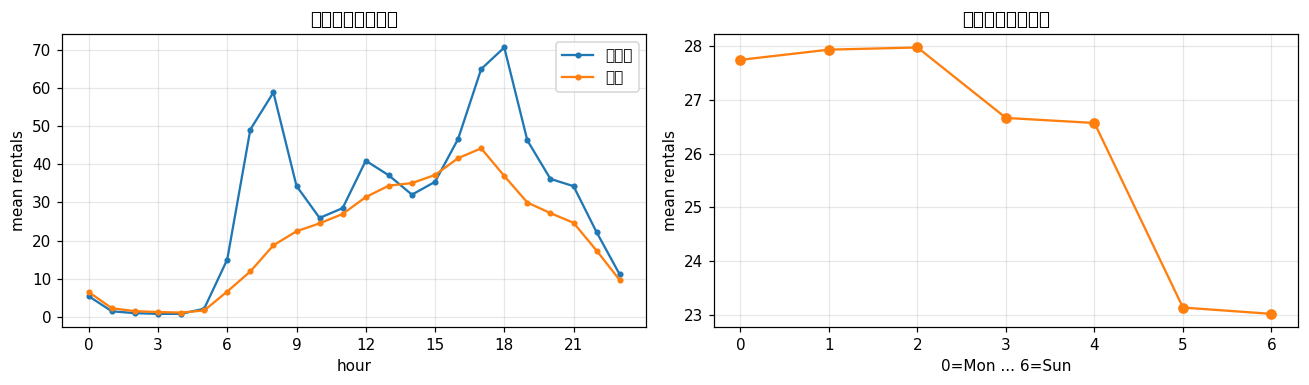

尖峰 17 時、離峰 4 時
整體平均 26.1551、中位數 20、零值比例 10.23%、偏態 1.6910


In [4]:
# 探索圖 1：時間模式
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
e = train_df.copy()
e["hour"] = e["datetime"].dt.hour
e["weekday"] = e["datetime"].dt.dayofweek

by_hour = e.groupby(["hour", "is_holiday"])[TARGET].mean().unstack()
by_hour.columns = ["工作日", "假日"]
by_hour.plot(ax=axes[0], marker="o", ms=3)
axes[0].set(title="每小時平均租借量", xlabel="hour", ylabel="mean rentals")
axes[0].set_xticks(range(0, 24, 3)); axes[0].grid(alpha=.3)

e.groupby("weekday")[TARGET].mean().plot(ax=axes[1], marker="o", color="tab:orange")
axes[1].set(title="星期幾平均租借量", xlabel="0=Mon ... 6=Sun", ylabel="mean rentals")
axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

peak, trough = by_hour.sum(axis=1).idxmax(), by_hour.sum(axis=1).idxmin()
print(f"尖峰 {peak} 時、離峰 {trough} 時")
print(f"整體平均 {train_df[TARGET].mean():.4f}、中位數 {train_df[TARGET].median():.0f}、"
      f"零值比例 {(train_df[TARGET] == 0).mean() * 100:.2f}%、偏態 {train_df[TARGET].skew():.4f}")

/tmp/ipykernel_925/1821249214.py:15: UserWarning: Glyph 25463 (\N{CJK UNIFIED IDEOGRAPH-6377}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/1821249214.py:15: UserWarning: Glyph 36939 (\N{CJK UNIFIED IDEOGRAPH-904B}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/1821249214.py:15: UserWarning: Glyph 20844 (\N{CJK UNIFIED IDEOGRAPH-516C}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/1821249214.py:15: UserWarning: Glyph 39208 (\N{CJK UNIFIED IDEOGRAPH-9928}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/1821249214.py:15: UserWarning: Glyph 31449 (\N{CJK UNIFIED IDEOGRAPH-7AD9}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/1821249214.py:15: UserWarning: Glyph 34399 (\N{CJK UNIFIED IDEOGRAPH-865F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/182124921

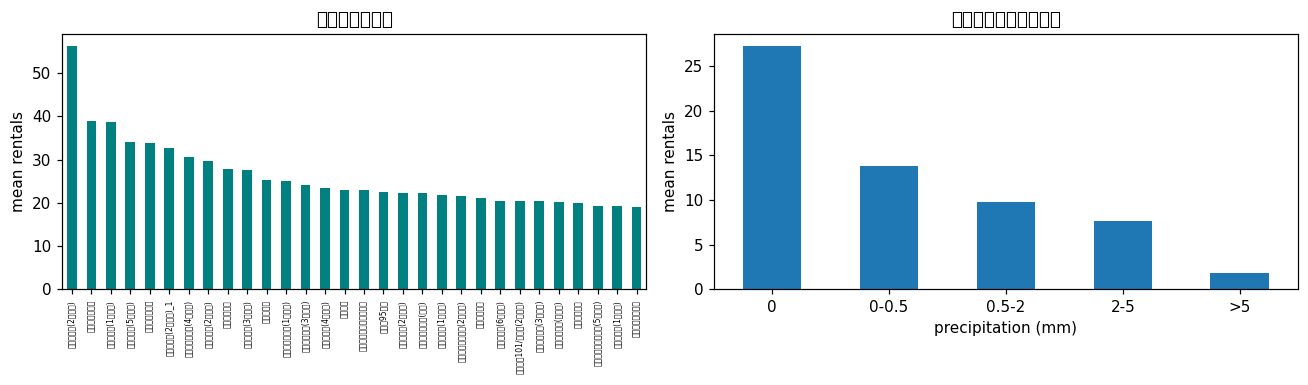

站點平均介於 19.1427 ~ 56.1823（差距 2.9 倍）
無雨 27.2387、0.5-2 mm 9.8220
與溫度相關 +0.2695、與濕度 -0.2893


In [5]:
# 探索圖 2：站點差異與天氣關係
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))

st = train_df.groupby("station")[TARGET].mean().sort_values(ascending=False)
st.plot(kind="bar", ax=axes[0], color="teal")
axes[0].set(title="各站平均租借量", ylabel="mean rentals", xlabel="")
axes[0].tick_params(axis="x", labelsize=5, rotation=90)

bins = [-.01, .01, .5, 2, 5, 100]
labels = ["0", "0-0.5", "0.5-2", "2-5", ">5"]
rain = train_df.groupby(pd.cut(train_df["precipitation"], bins, labels=labels),
                        observed=True)[TARGET].mean()
rain.plot(kind="bar", ax=axes[1], color="tab:blue", rot=0)
axes[1].set(title="降雨分組的平均租借量", xlabel="precipitation (mm)", ylabel="mean rentals")
plt.tight_layout(); plt.show()

print(f"站點平均介於 {st.min():.4f} ~ {st.max():.4f}（差距 {st.max()/st.min():.1f} 倍）")
print(f"無雨 {rain.iloc[0]:.4f}、0.5-2 mm {rain.loc['0.5-2']:.4f}")
print(f"與溫度相關 {train_df[['temperature', TARGET]].corr().iloc[0,1]:+.4f}、"
      f"與濕度 {train_df[['humidity', TARGET]].corr().iloc[0,1]:+.4f}")

/tmp/ipykernel_925/620333440.py:7: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/620333440.py:7: UserWarning: Glyph 22987 (\N{CJK UNIFIED IDEOGRAPH-59CB}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/620333440.py:7: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/620333440.py:7: UserWarning: Glyph 24067 (\N{CJK UNIFIED IDEOGRAPH-5E03}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 22987 (\N{CJK UNIFIED IDEOGRAPH-59CB}) missing from font(s) Dej

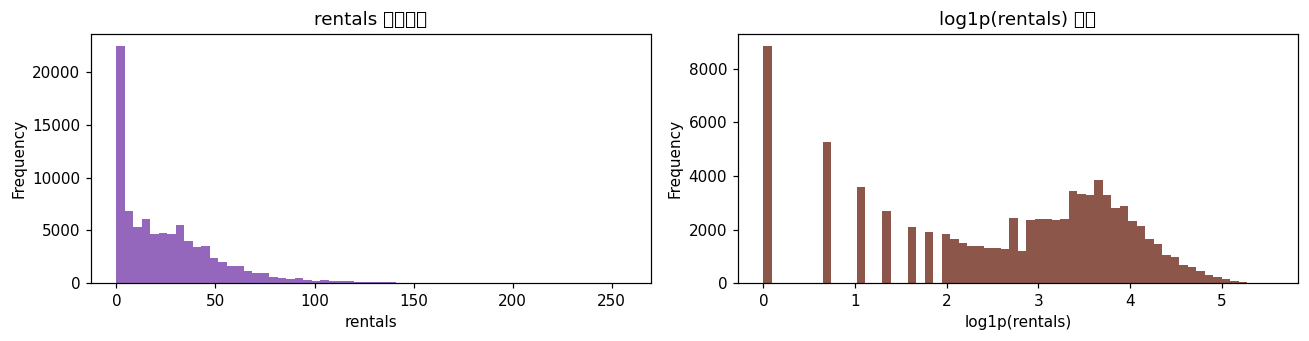

原始偏態 1.6910 → log1p 後 -0.5859


In [6]:
# 探索圖 3：目標值分布
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
train_df[TARGET].plot(kind="hist", bins=60, ax=axes[0], color="tab:purple")
axes[0].set(title="rentals 原始分布", xlabel="rentals")
np.log1p(train_df[TARGET]).plot(kind="hist", bins=60, ax=axes[1], color="tab:brown")
axes[1].set(title="log1p(rentals) 分布", xlabel="log1p(rentals)")
plt.tight_layout(); plt.show()
print(f"原始偏態 {train_df[TARGET].skew():.4f} → log1p 後 {np.log1p(train_df[TARGET]).skew():.4f}")

**觀察到的主要型態**

1. **雙峰通勤**：工作日在 8 時與 18 時各有一個尖峰，假日的曲線平緩許多且下午才上升。
   小時對需求的影響不是單調的，所以不能把 hour 當成連續數值丟進線性模型。
2. **站點差異大**：最忙的站平均需求是最冷清的數倍，而且各站的尖峰形狀不同
   （捷運出口旁是早上出發、住宅區是傍晚），所以需要站點 × 小時的交互作用。
3. **天氣影響明顯但不是主因**：降雨從 0 增加到 0.5–2 mm 時平均需求掉到約三分之一，
   溫度為正相關、濕度為負相關，但四個天氣欄位合起來只能解釋很小一部分變異。

In [7]:
# 官方 baseline：LinearRegression 只用四個天氣欄位
def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

def fit_eval(est, tr, va, target_col=TARGET):
    est = clone(est)
    est.fit(tr[FEATURE_COLS], tr[target_col])
    p_tr, p_va = est.predict(tr[FEATURE_COLS]), est.predict(va[FEATURE_COLS])
    return est, {"train_rmse": rmse(tr[target_col], p_tr), "train_r2": r2_score(tr[target_col], p_tr),
                 "val_rmse": rmse(va[target_col], p_va), "val_r2": r2_score(va[target_col], p_va)}

baseline_pipe = Pipeline([
    ("select", ColumnTransformer([("w", Pipeline([("impute", SimpleImputer(strategy="median"))]), WEATHER)],
                                 remainder="drop")),
    ("model", LinearRegression()),
])
_, base_raw = fit_eval(baseline_pipe, train_df, val_df)

log_pipe = TransformedTargetRegressor(regressor=clone(baseline_pipe), func=np.log1p, inverse_func=np.expm1)
_, base_log = fit_eval(log_pipe, train_df, val_df)

baseline_table = pd.DataFrame([{"目標": "raw", **base_raw}, {"目標": "log1p", **base_log}])
display(baseline_table.round(4))
print("官方 baseline.txt 記載：Train RMSE 25.0947 / Validation RMSE 29.3875")

,目標,train_rmse,train_r2,val_rmse,val_r2
0,raw,25.0947,0.1437,29.3875,0.0980
1,log1p,28.4616,-0.1015,38.1586,-0.5208


官方 baseline.txt 記載：Train RMSE 25.0947 / Validation RMSE 29.3875


**基準結果與目標轉換的取捨**

weather-only baseline 的驗證 RMSE 約 29.39、$R^2$ 僅 0.10，與官方 `baseline.txt` 一致。

目標值右偏（偏態 1.69、10% 為零），直覺上適合 log 轉換，但**在這個特徵集合下 log1p 反而更差**
（驗證 RMSE 38.16 vs 29.39）。原因是評分用的是原始尺度的 RMSE：log 空間的等權誤差換回原尺度後
會變成對大值寬鬆、對小值嚴苛，而 `expm1` 反轉換給的是條件中位數的近似、不是條件平均，
對 RMSE 這個以平均為最佳解的指標並不利。

因此**累加特徵比較（b）一律使用 raw 目標**，把變因固定在特徵上。
等特徵夠豐富、模型能描述各站各時段的結構之後，Part III(c) 會再對兩種目標各做一次比較。

## (b) 累加特徵工程

五組累積特徵，每一組都是前一組加上一類新資訊：

| 集合 | 新增內容 | 動機 |
|---|---|---|
| **F0** | 四個天氣欄位 | 官方 baseline |
| **F1** | + hour、weekday 的 one-hot + 假日指標 | 觀察 1 的雙峰通勤 |
| **F2** | + station one-hot | 觀察 2 的站點水準差異 |
| **F3** | + station×hour、holiday×hour 交互作用 | 各站尖峰形狀不同 |
| **F4** | + station×hour×weekday 交互作用 | 平日與週末的通勤曲線不同 |

模型固定為 **Ridge(α=10)**、數值欄位固定 StandardScaler、目標固定 raw，
讓表格的差異只反映特徵。

In [8]:
# 特徵轉換器與模型工廠
class CalendarFeatures(BaseEstimator, TransformerMixin):
    '''只依輸入欄位做固定規則轉換，不學習任何與目標有關的統計量。'''
    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        out = X.copy()
        dt = pd.to_datetime(out["datetime"])
        out["hour"] = dt.dt.hour.astype(str)
        out["weekday"] = dt.dt.dayofweek.astype(str)
        out["station"] = out["station"].astype(str)
        out["is_holiday"] = pd.to_numeric(out["is_holiday"]).astype(float)
        # 用 JSON 編碼組合鍵，避免站名本身含分隔符號造成碰撞
        out["station_hour"] = [json.dumps([s, h], ensure_ascii=False)
                               for s, h in zip(out["station"], out["hour"])]
        out["holiday_hour"] = [json.dumps([int(d), h])
                               for d, h in zip(out["is_holiday"], out["hour"])]
        out["station_hour_weekday"] = [json.dumps([s, h, d], ensure_ascii=False)
                                       for s, h, d in zip(out["station"], out["hour"], out["weekday"])]
        return out


class TrainingRangeClipper(BaseEstimator, TransformerMixin):
    '''只從 fit 的輸入學每欄的上下界，限制多項式項在訓練範圍外外推。'''
    def fit(self, X, y=None):
        v = np.asarray(X, dtype=float)
        self.data_min_, self.data_max_ = v.min(axis=0), v.max(axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.data_min_, self.data_max_)


def one_hot():
    opts = dict(handle_unknown="ignore", drop="first", dtype=np.float64)
    try:
        return OneHotEncoder(sparse_output=True, **opts)
    except TypeError:
        return OneHotEncoder(sparse=True, **opts)


CAT_BY_SET = {
    "F0": [], "F1": ["hour", "weekday"], "F2": ["hour", "weekday", "station"],
    "F3": ["hour", "weekday", "station", "station_hour", "holiday_hour"],
    "F4": ["hour", "weekday", "station", "station_hour", "holiday_hour", "station_hour_weekday"],
}
CAT_BY_SET["B"] = CAT_BY_SET["F4"]
CAT_BY_SET["B_stable"] = CAT_BY_SET["F4"]


def make_estimator(feature_set="F3", model="Ridge", alpha=10.0, scaler="standard",
                   target="raw", max_iter=2000):
    '''回傳未 fit 的完整 Pipeline；所有可學習的步驟都在裡面。'''
    scale = {"none": "passthrough", "standard": StandardScaler(), "minmax": MinMaxScaler()}[scaler]
    steps = [("impute", SimpleImputer(strategy="median"))]
    if feature_set == "B_stable":
        steps.append(("weather_bounds", TrainingRangeClipper()))
    steps.append(("scale", scale))
    if feature_set in {"B", "B_stable"}:
        # 高次項只作用在四個天氣欄位，不碰上千個 one-hot 欄位
        steps += [("poly", PolynomialFeatures(degree=4 if feature_set == "B" else 2, include_bias=False)),
                  ("poly_scale", StandardScaler())]

    blocks = [("numeric", Pipeline(steps), WEATHER)]
    if feature_set != "F0":
        blocks.append(("holiday", "passthrough", ["is_holiday"]))
    cats = CAT_BY_SET[feature_set]
    if cats:
        blocks.append(("categorical", one_hot(), cats))
    pre = ColumnTransformer(blocks, remainder="drop", sparse_threshold=1.0)

    if model == "LinearRegression":
        reg = LinearRegression()
    elif model == "Ridge":
        reg = Ridge(alpha=float(alpha), solver="lsqr", tol=1e-6)
    elif model == "SGDRegressor":
        reg = SGDRegressor(loss="squared_error", penalty=None, learning_rate="invscaling",
                           eta0=0.01, power_t=0.25, max_iter=max_iter, tol=1e-3,
                           n_iter_no_change=10, early_stopping=False,
                           random_state=SEED, shuffle=True)
    else:
        raise ValueError(f"本作業不允許的模型: {model}")

    pipe = Pipeline([("calendar", CalendarFeatures()), ("preprocess", pre), ("model", reg)])
    if target == "log1p":
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
    return pipe


def n_features_of(fitted):
    inner = fitted.regressor_ if isinstance(fitted, TransformedTargetRegressor) else fitted
    coef = inner.named_steps["model"].coef_
    return int(np.asarray(coef).ravel().shape[0])

print("特徵轉換器與模型工廠就緒")

特徵轉換器與模型工廠就緒


In [9]:
# F0 → F4 累加比較（模型、目標、縮放全部固定）
rows = []
for fs in ["F0", "F1", "F2", "F3", "F4"]:
    est, m = fit_eval(make_estimator(fs, "Ridge", alpha=10.0, scaler="standard", target="raw"),
                      train_df, val_df)
    rows.append({"集合": fs, "特徵數": n_features_of(est), **m})
    print(f"{fs} 完成")

feature_table = pd.DataFrame(rows)
display(feature_table.round(4))

F0 完成
F1 完成
F2 完成
F3 完成
F4 完成


,集合,特徵數,train_rmse,train_r2,val_rmse,val_r2
0,F0,4,25.0947,0.1437,29.3872,0.0980
1,F1,34,19.4867,0.4836,22.2800,0.4815
2,F2,63,17.8116,0.5686,20.0818,0.5788
3,F3,829,14.1882,0.7263,16.1728,0.7268
4,F4,5868,12.9541,0.7718,14.9802,0.7656


In [10]:
# 每一步帶來的改善
d = feature_table.set_index("集合")["val_rmse"]
for a, b in zip(["F0", "F1", "F2", "F3"], ["F1", "F2", "F3", "F4"]):
    print(f"{a} → {b}: 驗證 RMSE {d[a]:.4f} → {d[b]:.4f}　改善 {d[a]-d[b]:+.4f}")

F0 → F1: 驗證 RMSE 29.3872 → 22.2800　改善 +7.1073
F1 → F2: 驗證 RMSE 22.2800 → 20.0818　改善 +2.1982
F2 → F3: 驗證 RMSE 20.0818 → 16.1728　改善 +3.9090
F3 → F4: 驗證 RMSE 16.1728 → 14.9802　改善 +1.1926


**哪些特徵最有效**

加入時間 one-hot（F0→F1）帶來最大的單步改善，驗證 RMSE 下降約 7.1，
印證觀察 1 的通勤雙峰是需求最主要的結構。
其次是站點 × 小時交互作用（F2→F3）再降約 3.9，代表各站的尖峰形狀確實不同，
只用一條共同的時間曲線加上各站的固定偏移不足以描述。
F3→F4 的三階交互作用仍有改善但幅度縮小，而特徵數從 829 膨脹到 5868，
邊際效益明顯遞減。

**編碼選擇的理由（從線性模型的角度）**

- **hour、weekday 用 one-hot 而非數值**：線性模型對數值輸入只能給單調的線性效果，
  但需求在 8 時與 18 時各有尖峰、凌晨最低，不是單調關係。
  one-hot 讓每個時段擁有自己的截距偏移，等於用線性模型表達任意形狀的日週期。
  同理 23 時與 0 時在數值上差 23、實際上相鄰，數值編碼會給出錯誤的距離。
- **station 用 one-hot**：站名是無序類別，任何數值編碼都會強加不存在的順序與間距。
- **交互作用用組合鍵再 one-hot**：線性模型本身只能相加，
  要表達「A 站的 8 點」這種非相加效果，必須把組合顯式展開成欄位。
- **`drop="first"`**：one-hot 各欄相加恆為 1，與截距共線會讓 $X^\top X$ 奇異；
  丟掉一個基準類別可避免這個問題（其效果被吸收進截距）。
- **`handle_unknown="ignore"`**：驗證或測試月份若出現訓練期沒看過的組合，
  編碼為全零而不是報錯。
- 天氣維持數值並標準化，因為它們本來就是有序的連續量。

## (c) 特徵縮放

固定 **F2** 特徵集與 raw 目標，只改變數值欄位（四個天氣欄）的前處理，
比較三種縮放 × 三種模型：

- **閉式解**：`LinearRegression`
- **正則化**：`Ridge(α=10)`
- **梯度下降**：`SGDRegressor`（`penalty=None` 以隔離最佳化效應，
  `learning_rate='invscaling'`、`eta0=0.01`、`power_t=0.25`、`tol=1e-3`、`max_iter=2000`）

類別欄位在三種設定下都用同一套 one-hot，不受縮放影響。

In [11]:
# 三種縮放 × 三種模型
rows = []
for model in ["LinearRegression", "Ridge", "SGDRegressor"]:
    for sc in ["none", "standard", "minmax"]:
        est, m = fit_eval(make_estimator("F2", model, alpha=10.0, scaler=sc, target="raw"),
                          train_df, val_df)
        inner = est.named_steps["model"]
        rows.append({"模型": model, "縮放": sc, "驗證 RMSE": m["val_rmse"],
                     "SGD epochs": int(inner.n_iter_) if model == "SGDRegressor" else None})
        print(f"{model:18s} {sc:9s} 完成")

scaling_table = pd.DataFrame(rows)
display(scaling_table.round(4))

LinearRegression   none      完成
LinearRegression   standard  完成
LinearRegression   minmax    完成
Ridge              none      完成
Ridge              standard  完成
Ridge              minmax    完成


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:1608: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


SGDRegressor       none      完成
SGDRegressor       standard  完成
SGDRegressor       minmax    完成


,模型,縮放,驗證 RMSE,SGD epochs
0,LinearRegression,none,2.005990e+01,NaN
1,LinearRegression,standard,2.005990e+01,NaN
2,LinearRegression,minmax,2.005980e+01,NaN
3,Ridge,none,2.008200e+01,NaN
4,Ridge,standard,2.008180e+01,NaN
5,Ridge,minmax,2.009790e+01,NaN
6,SGDRegressor,none,5.763509e+06,2000.0
7,SGDRegressor,standard,2.001760e+01,79.0
8,SGDRegressor,minmax,2.006170e+01,72.0


**用 Part I(b) 解釋觀察到的差異**

1. **`LinearRegression` 三種縮放幾乎相同**（差異在小數點後第四位）。
   縮放是可逆的線性變換，閉式解所能表達的函數空間不變，最佳解也不變；
   殘差只來自浮點運算。這對應 Part I(b) 中「OLS 的預測不因單位換算而改變」。

2. **`Ridge` 隨縮放改變**。固定的 $\alpha$ 對不同尺度的欄位施加不同強度的收縮：
   縮放後各欄係數的量級被重新分配，懲罰項 $\alpha\lVert w\rVert^2$ 的相對權重也跟著變。
   這正是 Part I(b) 的結論 —— 把輸入除以 10、係數需放大 10 倍，懲罰卻放大 100 倍，
   所以 Ridge 不具尺度不變性。此處四個天氣欄的尺度差距不大（溫度 ~10¹、濕度 ~10²），
   因此差異比 toy 例子溫和。

3. **`SGDRegressor` 在未縮放時完全失敗**，RMSE 爆到 10⁶ 量級並跑滿 2000 個 epoch；
   標準化後降到正常水準且在數十個 epoch 內收斂。
   這對應 Part I(b) 的第二點：未縮放時 Hessian $X^\top X$ 的條件數很大，
   `eta0=0.01` 對最陡方向而言超過 $2/L$ 的穩定界限，更新在該方向發散。
   標準化把各欄拉到同一量級、壓低條件數，同一個學習率就同時滿足穩定與收斂速度。
   閉式解不經過迭代，所以完全不受這個問題影響 —— 這是三者最關鍵的差別。

---
# Part III　Learning Curves and Forecasting

## 學習曲線工具

若執行環境已定義課程提供的 `plot_learning_curve`（例如從 `A2_starter.ipynb` 貼入），
下一格會直接採用；否則使用等價的實作：以**時間順序**切出交叉驗證折，
橫軸為訓練樣本數，縱軸為訓練與驗證 RMSE。

採時間順序切分而非隨機切分，是因為同一小時的 30 個站點高度相關，
隨機切分會讓同一小時同時出現在訓練與驗證側而高估表現。

In [12]:
OFFICIAL_HELPER = globals().get("plot_learning_curve")
USING_OFFICIAL = callable(OFFICIAL_HELPER)
print("使用課程提供的 plot_learning_curve" if USING_OFFICIAL
      else "課程 helper 未定義，使用等價的時間切分實作")


def temporal_folds(frame, n_folds=3):
    '''依 datetime 做向前滾動切分；同一小時的所有站點必定同側。'''
    hours = np.sort(frame["datetime"].unique())
    edges = np.linspace(0, len(hours), n_folds + 2).astype(int)
    for k in range(1, n_folds + 1):
        tr_hours, va_hours = set(hours[:edges[k]]), set(hours[edges[k]:edges[k + 1]])
        tr = frame.index[frame["datetime"].isin(tr_hours)].to_numpy()
        va = frame.index[frame["datetime"].isin(va_hours)].to_numpy()
        if len(tr) and len(va):
            yield tr, va


def learning_curve_data(estimator, frame, sizes=(0.2, 0.4, 0.6, 0.8, 1.0), n_folds=3):
    '''回傳 (訓練樣本數, 訓練 RMSE, 驗證 RMSE)；每個點都重新 fit 一條新 pipeline。'''
    folds = list(temporal_folds(frame, n_folds))
    n_list, tr_list, va_list = [], [], []
    for frac in sizes:
        tr_scores, va_scores, counts = [], [], []
        for tr_idx, va_idx in folds:
            take = tr_idx[-max(1, int(len(tr_idx) * frac)):]   # 取最靠近驗證期的一段
            tr_part, va_part = frame.loc[take], frame.loc[va_idx]
            est = clone(estimator)
            est.fit(tr_part[FEATURE_COLS], tr_part[TARGET])
            tr_scores.append(rmse(tr_part[TARGET], est.predict(tr_part[FEATURE_COLS])))
            va_scores.append(rmse(va_part[TARGET], est.predict(va_part[FEATURE_COLS])))
            counts.append(len(take))
        n_list.append(int(np.mean(counts)))
        tr_list.append(float(np.mean(tr_scores)))
        va_list.append(float(np.mean(va_scores)))
    return np.array(n_list), np.array(tr_list), np.array(va_list)


def draw_curves(specs, suptitle):
    '''specs: [(名稱, estimator)]；並排畫出學習曲線並回傳終端數值。'''
    fig, axes = plt.subplots(1, len(specs), figsize=(6 * len(specs), 4))
    axes = np.atleast_1d(axes)
    summary = []
    for ax, (name, est) in zip(axes, specs):
        if USING_OFFICIAL:
            OFFICIAL_HELPER(est, train_df[FEATURE_COLS], train_df[TARGET])
            n, tr, va = learning_curve_data(est, train_df)
        else:
            n, tr, va = learning_curve_data(est, train_df)
        ax.plot(n, tr, "o-", label="training RMSE")
        ax.plot(n, va, "s--", label="CV RMSE")
        ax.set(title=name, xlabel="number of training examples", ylabel="RMSE")
        ax.legend(); ax.grid(alpha=.3)
        summary.append({"模型": name, "末端訓練 RMSE": tr[-1],
                        "末端驗證 RMSE": va[-1], "差距": va[-1] - tr[-1]})
        print(f"{name} 完成")
    fig.suptitle(suptitle); plt.tight_layout(); plt.show()
    return pd.DataFrame(summary)

print("學習曲線工具就緒")

課程 helper 未定義，使用等價的時間切分實作
學習曲線工具就緒


## (a) 診斷

- **Model A（預期 underfit）**：只用四個天氣欄位的 `LinearRegression`。
  刻意不給任何時間或站點資訊，模型無法表達通勤結構。
- **Model B（預期 overfit）**：F4 的三階交互作用（5868 欄）再加上
  **未限制範圍的四次天氣多項式**，且 `LinearRegression` 不做任何正則化。

Model A — weather-only OLS 完成


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Model B — degree-4 poly + interactions, no reg. 完成


/tmp/ipykernel_925/2000825015.py:57: UserWarning: Glyph 25913 (\N{CJK UNIFIED IDEOGRAPH-6539}) missing from font(s) DejaVu Sans.
  fig.suptitle(suptitle); plt.tight_layout(); plt.show()
/tmp/ipykernel_925/2000825015.py:57: UserWarning: Glyph 21892 (\N{CJK UNIFIED IDEOGRAPH-5584}) missing from font(s) DejaVu Sans.
  fig.suptitle(suptitle); plt.tight_layout(); plt.show()
/tmp/ipykernel_925/2000825015.py:57: UserWarning: Glyph 21069 (\N{CJK UNIFIED IDEOGRAPH-524D}) missing from font(s) DejaVu Sans.
  fig.suptitle(suptitle); plt.tight_layout(); plt.show()
/tmp/ipykernel_925/2000825015.py:57: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  fig.suptitle(suptitle); plt.tight_layout(); plt.show()
/tmp/ipykernel_925/2000825015.py:57: UserWarning: Glyph 23416 (\N{CJK UNIFIED IDEOGRAPH-5B78}) missing from font(s) DejaVu Sans.
  fig.suptitle(suptitle); plt.tight_layout(); plt.show()
/tmp/ipykernel_925/2000825015.py:57: UserWarning: Glyph 32722 (\N{CJK 

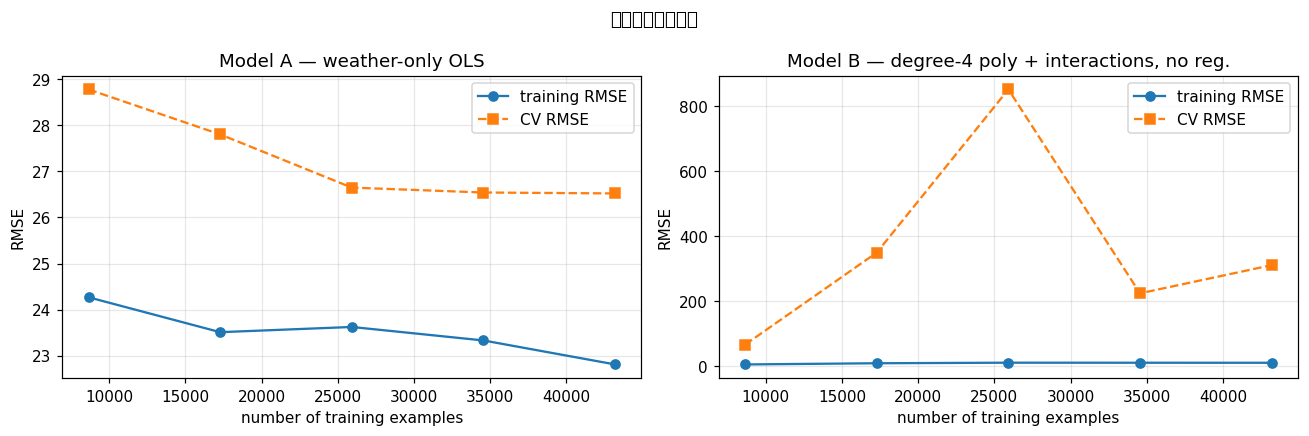

,模型,末端訓練 RMSE,末端驗證 RMSE,差距
0,Model A — weather-only OLS,22.8109,26.5208,3.7098
1,"Model B — degree-4 poly + interactions, no reg.",9.7479,310.2520,300.5041


In [13]:
model_A_before = make_estimator("F0", "LinearRegression", target="raw")
model_B_before = make_estimator("B", "LinearRegression", target="raw")

before_table = draw_curves([("Model A — weather-only OLS", model_A_before),
                            ("Model B — degree-4 poly + interactions, no reg.", model_B_before)],
                           "改善前的學習曲線")
display(before_table.round(4))

**Model A：高偏差（underfitting）**

兩條曲線都停在很高的位置而且幾乎重合、差距很小。訓練誤差本身就降不下來，
代表模型的表達能力不足以描述資料，不是記憶不足的問題。
曲線在最大訓練量處已經走平，**再多同類型的資料幫助有限** ——
需要的是更豐富的特徵。

**Model B：高變異（overfitting）**

訓練誤差很低但驗證誤差高出數個量級，兩者差距巨大。
四次天氣多項式在訓練範圍外急遽發散，加上 5868 欄交互作用且無正則化，
模型記住了訓練折的雜訊。
曲線隨訓練量增加而收斂，**增加資料會有幫助**，但更有效的是降低模型複雜度
或加上正則化。

## (b) 補救

| 模型 | 診斷 | 採取的補救 |
|---|---|---|
| A | 高偏差 | **增加特徵表達力**：改用 F4（時間、站點、交互作用） |
| B | 高變異 | **降低複雜度並正則化**：多項式降為二次、天氣輸入先裁切到訓練範圍、改用 Ridge |

每個模型只套用一個與診斷相符的補救。

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Model A after — richer features 完成


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Model B after — clipped degree-2 + Ridge 完成


/tmp/ipykernel_925/2000825015.py:57: UserWarning: Glyph 25913 (\N{CJK UNIFIED IDEOGRAPH-6539}) missing from font(s) DejaVu Sans.
  fig.suptitle(suptitle); plt.tight_layout(); plt.show()
/tmp/ipykernel_925/2000825015.py:57: UserWarning: Glyph 21892 (\N{CJK UNIFIED IDEOGRAPH-5584}) missing from font(s) DejaVu Sans.
  fig.suptitle(suptitle); plt.tight_layout(); plt.show()
/tmp/ipykernel_925/2000825015.py:57: UserWarning: Glyph 24460 (\N{CJK UNIFIED IDEOGRAPH-5F8C}) missing from font(s) DejaVu Sans.
  fig.suptitle(suptitle); plt.tight_layout(); plt.show()
/tmp/ipykernel_925/2000825015.py:57: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  fig.suptitle(suptitle); plt.tight_layout(); plt.show()
/tmp/ipykernel_925/2000825015.py:57: UserWarning: Glyph 23416 (\N{CJK UNIFIED IDEOGRAPH-5B78}) missing from font(s) DejaVu Sans.
  fig.suptitle(suptitle); plt.tight_layout(); plt.show()
/tmp/ipykernel_925/2000825015.py:57: UserWarning: Glyph 32722 (\N{CJK 

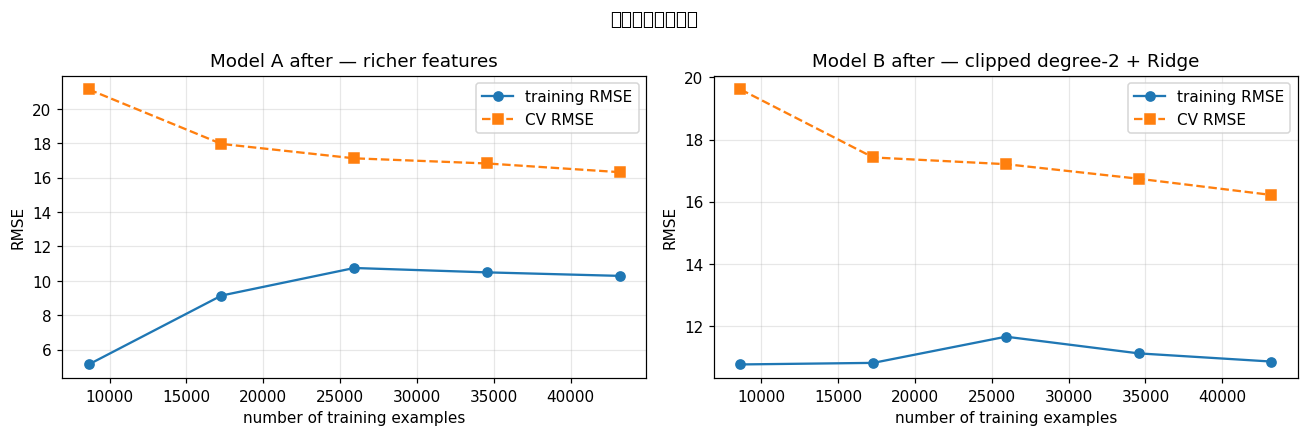

,模型,末端訓練 RMSE,末端驗證 RMSE,差距
0,Model A after — richer features,10.2872,16.3279,6.0407
1,Model B after — clipped degree-2 + Ridge,10.8641,16.2192,5.3551


,模型_before,末端驗證 RMSE_before,模型_after,末端驗證 RMSE_after
0,Model A — weather-only OLS,26.5208,Model A after — richer features,16.3279
1,"Model B — degree-4 poly + interactions, no reg.",310.2520,Model B after — clipped degree-2 + Ridge,16.2192


In [14]:
model_A_after = make_estimator("F4", "LinearRegression", target="raw")
model_B_after = make_estimator("B_stable", "Ridge", alpha=10.0, scaler="standard", target="raw")

after_table = draw_curves([("Model A after — richer features", model_A_after),
                           ("Model B after — clipped degree-2 + Ridge", model_B_after)],
                          "改善後的學習曲線")
display(after_table.round(4))

cmp = before_table.merge(after_table, left_index=True, right_index=True,
                         suffixes=("_before", "_after"))[
    ["模型_before", "末端驗證 RMSE_before", "模型_after", "末端驗證 RMSE_after"]]
display(cmp.round(4))

**兩個補救都有效**

Model A 加入時間與站點結構後，驗證 RMSE 大幅下降，而且訓練誤差同步下降 ——
這正是高偏差被解決的特徵（若原本是高變異，加特徵只會讓情況更糟）。

Model B 的驗證誤差從數百降到與訓練誤差同一量級，兩線差距收斂。
三項處理合起來生效：裁切天氣輸入避免多項式在範圍外爆炸、降次減少參數、
Ridge 收縮剩餘係數。

## (c) 選模與排行榜

**只用 5 月驗證集選模**。候選為 F3、F4、B_stable 三種特徵，
各搭配 raw 與 log1p 目標、以及數個 Ridge $\alpha$。
Part III(a) 已診斷出未正則化的四次多項式 B 不穩定，不列入最終候選。

In [15]:
# 只依 5 月驗證集選模
candidates = []
for fs in ["F3", "F4", "B_stable"]:
    for target in ["raw", "log1p"]:
        for alpha in [0.1, 1.0, 10.0, 100.0]:
            candidates.append((fs, target, alpha))

rows = []
for fs, target, alpha in candidates:
    est, m = fit_eval(make_estimator(fs, "Ridge", alpha=alpha, scaler="standard", target=target),
                      train_df, val_df)
    rows.append({"特徵": fs, "目標": target, "alpha": alpha, "五月 RMSE": m["val_rmse"]})

selection = pd.DataFrame(rows).sort_values("五月 RMSE").reset_index(drop=True)
display(selection.head(10).round(4))

best = selection.iloc[0]
print(f"\n選定：{best['特徵']} + Ridge(alpha={best['alpha']}) + 目標={best['目標']}")

# 保留「選模當下」的模型：只用 1-4 月訓練，5 月完全沒看過。
# 它的 5 月 RMSE 才是沒有洩漏的泛化估計，可以拿來和測試分數比較。
selection_model, selected_metrics = fit_eval(
    make_estimator(best["特徵"], "Ridge", alpha=float(best["alpha"]),
                   scaler="standard", target=best["目標"]),
    train_df, val_df)
SELECTED_VAL_RMSE = selected_metrics["val_rmse"]
val_pred = np.clip(selection_model.predict(val_df[FEATURE_COLS]), 0, None)
print(f"選模模型（僅 1-4 月訓練）的 5 月 RMSE：{SELECTED_VAL_RMSE:.4f}")

,特徵,目標,alpha,五月 RMSE
0,B_stable,log1p,0.1,13.1624
1,B_stable,log1p,1.0,13.1692
2,B_stable,log1p,10.0,13.4819
3,B_stable,raw,0.1,14.0862
4,B_stable,raw,1.0,14.1209
5,F4,log1p,0.1,14.1575
6,F4,log1p,1.0,14.1817
7,B_stable,raw,10.0,14.5115
8,F4,log1p,10.0,14.5182
9,F4,raw,0.1,14.5524



選定：B_stable + Ridge(alpha=0.1) + 目標=log1p
選模模型（僅 1-4 月訓練）的 5 月 RMSE：13.1624


In [16]:
# 以 1-5 月全部資料重訓，預測 6 月。
# 重訓後的模型已經看過 5 月，不能再用 5 月評估，上一格的 13.16 才是泛化估計。
final_est = make_estimator(best["特徵"], "Ridge", alpha=float(best["alpha"]),
                           scaler="standard", target=best["目標"])
final_est.fit(train_all[FEATURE_COLS], train_all[TARGET])

pred = final_est.predict(test_df[FEATURE_COLS])
pred = np.clip(pred, 0, None)          # 負值裁為 0，不四捨五入
print(f"預測 {len(pred):,} 筆｜最小 {pred.min():.4f}｜最大 {pred.max():.4f}｜平均 {pred.mean():.4f}")

id_col, target_col = sample_sub.columns[0], sample_sub.columns[1]
submission = sample_sub.copy()
submission[target_col] = pd.Series(pred, index=test_df.index).reindex(
    test_df.set_index("id").index.get_indexer(sample_sub[id_col])).to_numpy()
assert submission[target_col].notna().all(), "提交檔有未對應到的 id"
submission.to_csv("submission.csv", index=False)
print(f"已輸出 submission.csv（欄名 {list(submission.columns)}，依 sample_submission 的列順序）")
display(submission.head())

預測 21,600 筆｜最小 0.0000｜最大 200.9428｜平均 27.3886
已輸出 submission.csv（欄名 ['id', 'rentals']，依 sample_submission 的列順序）


,id,rentals
0,108720,9.133498
1,108721,5.219850
2,108722,5.419596
3,108723,10.818490
4,108724,23.335183


/tmp/ipykernel_925/2059458314.py:17: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/2059458314.py:17: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/2059458314.py:17: UserWarning: Glyph 23526 (\N{CJK UNIFIED IDEOGRAPH-5BE6}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/2059458314.py:17: UserWarning: Glyph 38555 (\N{CJK UNIFIED IDEOGRAPH-969B}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/2059458314.py:17: UserWarning: Glyph 38928 (\N{CJK UNIFIED IDEOGRAPH-9810}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/2059458314.py:17: UserWarning: Glyph 28204 (\N{CJK UNIFIED IDEOGRAPH-6E2C}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_925/2059458314.py:17: Us

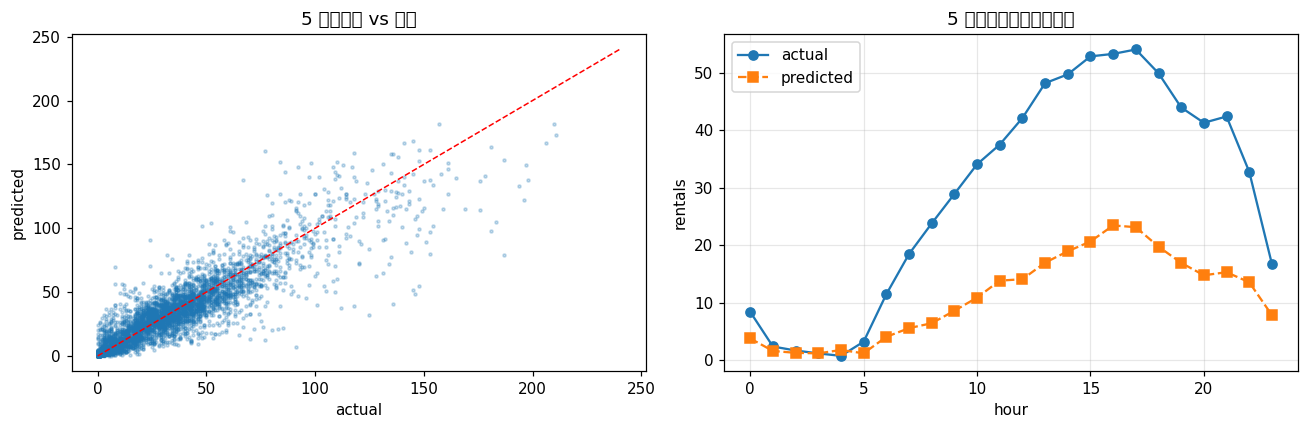

選模模型的 5 月驗證 RMSE：13.1624
官方 TA baseline 測試 RMSE：24.2461


In [17]:
# 驗證集預測表現（使用上面「只以 1-4 月訓練」的選模模型）
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
take = np.random.default_rng(SEED).choice(len(val_df), size=min(5000, len(val_df)), replace=False)
axes[0].scatter(val_df[TARGET].to_numpy()[take], val_pred[take], s=4, alpha=.25)
lim = [0, max(val_df[TARGET].max(), val_pred.max())]
axes[0].plot(lim, lim, "r--", lw=1)
axes[0].set(title="5 月：實際 vs 預測", xlabel="actual", ylabel="predicted")

day = val_df[val_df["datetime"].dt.date == val_df["datetime"].dt.date.iloc[0]]
hourly = day.groupby(day["datetime"].dt.hour)[TARGET].mean()
hourly_pred = pd.Series(val_pred[:len(val_df)], index=val_df.index).loc[day.index] \
                .groupby(day["datetime"].dt.hour).mean()
axes[1].plot(hourly.index, hourly.values, "o-", label="actual")
axes[1].plot(hourly_pred.index, hourly_pred.values, "s--", label="predicted")
axes[1].set(title="5 月第一天的每小時平均", xlabel="hour", ylabel="rentals")
axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

TA_BASELINE_TEST_RMSE = 24.2461   # 來自 baseline.txt
print(f"選模模型的 5 月驗證 RMSE：{SELECTED_VAL_RMSE:.4f}")
print(f"官方 TA baseline 測試 RMSE：{TA_BASELINE_TEST_RMSE}")

**排行榜結果**

把上面輸出的 `submission.csv` 上傳到課程 Kaggle 排行榜後，
測試 RMSE 為 **12.37017**，低於官方 TA baseline 的 **24.2461**（改善約 49%），
達到排行榜項目的滿分條件。

**驗證 RMSE 是可靠的估計嗎？**

5 月驗證 RMSE 約 13.16，測試 RMSE 12.37，驗證值比測試值高約 0.79（6%），
方向上偏保守而非樂觀，以泛化估計而言算是可靠。
兩者仍有差距的原因有二：最終模型是用 1–5 月全部資料重訓的，比選模時多了一個月的資料；
而且 6 月的天氣與需求水準本來就和 5 月不同。
因此這個差距不能單純解讀成「模型泛化得更好」，兩個條件不完全可比。